In [2]:
from google.colab import drive
#drive.mount('/content/drive')
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [3]:
import pandas as pd
import glob

### forest

file_paths = [
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ OSFL .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ RCKI .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ WETA .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ YRWA .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Forest/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ HAFL .csv'
]

# Remove any accidental extra spaces from filenames
file_paths = [path.strip() for path in file_paths]

# Read and concatenate
dfs = [pd.read_csv(path) for path in file_paths]
combined_forest = pd.concat(dfs, ignore_index=True)

### grassland

file_paths = [
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ GRSP .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ LBCU .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ MOBL .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ UPSA .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Grassland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ WEME .csv'
]

# Remove any accidental extra spaces from filenames
file_paths = [path.strip() for path in file_paths]

# Read and concatenate
dfs = [pd.read_csv(path) for path in file_paths]
combined_grassland = pd.concat(dfs, ignore_index=True)

### woodland

file_paths = [
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ BGGN .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ CAKI .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ EABL .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ PLVI .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ SAPH .csv'
]

# Remove any accidental extra spaces from filenames
file_paths = [path.strip() for path in file_paths]

# Read and concatenate
dfs = [pd.read_csv(path) for path in file_paths]
combined_woodland = pd.concat(dfs, ignore_index=True)

### shrubland

file_paths = [
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ GRFL .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ LOSH .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ SATH .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ WEKI .csv',
    '/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ YEWA .csv'
]

# Remove any accidental extra spaces from filenames
file_paths = [path.strip() for path in file_paths]

# Read and concatenate
dfs = [pd.read_csv(path) for path in file_paths]
combined_shrubland = pd.concat(dfs, ignore_index=True)

In [4]:
# Combine woodland and shrubland data
all_combined = pd.concat([combined_forest, combined_grassland, combined_woodland, combined_shrubland], ignore_index=True)
print(all_combined.shape)
# Drop duplicate rows
all_combined = all_combined.drop_duplicates(subset=['PointLatit', 'PointLongi'])

# Check the result
#print(all_combined.shape)
#print(all_combined.head())

# (Optional) Save the final combined dataframe
#all_combined.to_csv('/content/drive/My Drive/SHAP_multipredictors/Guild/all_combined.csv', index=False)


(417754, 12)


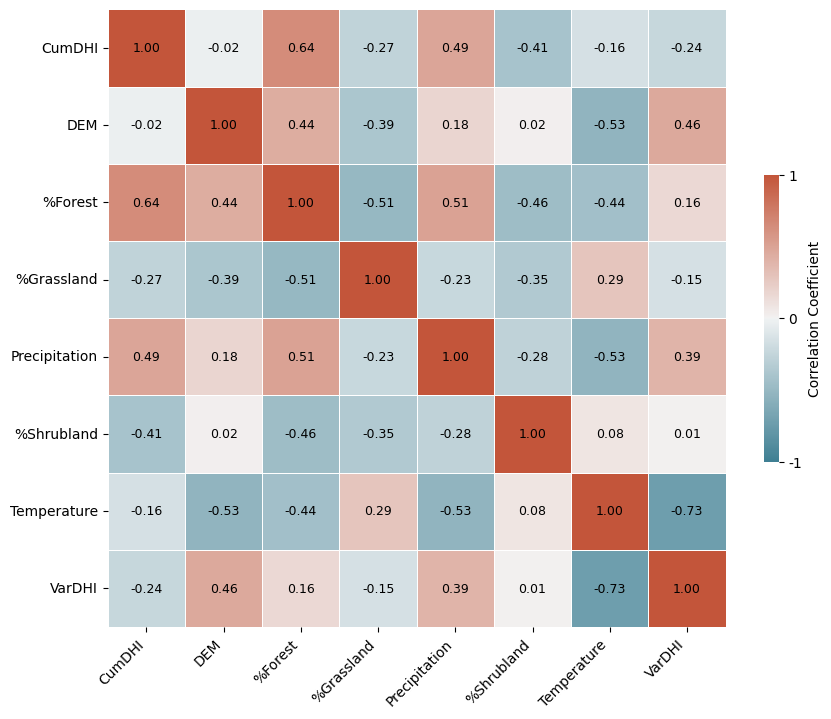

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select columns 4 to 12
selected_columns = all_combined.iloc[:, 4:12]

# Compute correlation matrix
correlation_matrix = selected_columns.corr()

# Define custom tick labels
custom_labels = ['CumDHI', 'DEM', '%Forest', '%Grassland', 'Precipitation', '%Shrubland', 'Temperature', 'VarDHI']

# Set up the figure
fig, ax = plt.subplots(figsize=(9, 8))

# Draw heatmap and capture the colorbar object
heatmap = sns.heatmap(
    correlation_matrix,
    cmap=sns.diverging_palette(220, 20, as_cmap=True),
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.4, "label": "Correlation Coefficient"},
    annot=True,
    fmt=".2f",
    annot_kws={"size": 9, "color": "black"},
    xticklabels=custom_labels,
    yticklabels=custom_labels
)

# Set x and y axis tick labels
ax.set_xticklabels(custom_labels, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(custom_labels, rotation=0, fontsize=10)

# Manually set colorbar ticks to -1, 0, 1
colorbar = heatmap.collections[0].colorbar
colorbar.set_ticks([-1, 0, 1])
colorbar.set_ticklabels(['-1', '0', '1'])

# Layout
plt.tight_layout()
plt.show()



In [1]:
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import matplotlib.pyplot as plt

# Create custom norm that stretches the white region from -0.2 to 0.2
norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)

# Now plot the heatmap using this norm
sns.heatmap(
    correlation_matrix,
    cmap=sns.diverging_palette(220, 20, as_cmap=True),
    norm=norm,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation Coefficient"},
    annot=True,
    fmt=".2f",
    annot_kws={"size": 3, "color": "black"},
    xticklabels=custom_labels,
    yticklabels=custom_labels
)

NameError: name 'correlation_matrix' is not defined

## GINI Index

In [20]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import r2_score

#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["HAFL","OSFL", "RCKI","WETA","YRWA"]  #Forest
#species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] #woodland
species_list = ["GRFL","LOSH","WEKI","SATH","YEWA"]  #shrubland
for species in species_list:
  data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Shrubland/32x32/Raster_extracted_Raster_extracted_Pred_ {species} .csv")
  y = data['Predicted']
  predictors = data.iloc[:,4:12]

  X = pd.concat([predictors], axis=1)
  scaler = StandardScaler()
  X_scaled = scaler.fit_transform(X)
  X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
  # Split the data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
  # Create and train the Random Forest model
  model = RandomForestRegressor(n_estimators=1000, random_state=42)
  model.fit(X_train, y_train)

  # Get feature importance (Gini importance / mean decrease in impurity)
  feature_importance = model.feature_importances_

  # Create a DataFrame for easy visualization
  importance_df = pd.DataFrame({
      'Feature': X.columns,
      'Importance': feature_importance
  }).sort_values(by='Importance', ascending=False)
  print(species)
  print(importance_df)

GRFL
                Feature  Importance
3          VarDHI_32x32    0.622433
1                   DEM    0.093385
2          CumDHI_32x32    0.070978
7        precip_average    0.051440
6          tmax_average    0.050502
5     Forest_percentage    0.044352
4  Shrubland_percentage    0.039457
0  Grassland_percentage    0.027454
LOSH
                Feature  Importance
2          CumDHI_32x32    0.593351
1                   DEM    0.102901
3          VarDHI_32x32    0.061567
5     Forest_percentage    0.057858
6          tmax_average    0.053145
7        precip_average    0.052893
0  Grassland_percentage    0.044735
4  Shrubland_percentage    0.033551
WEKI
                Feature  Importance
3          VarDHI_32x32    0.661846
1                   DEM    0.082143
2          CumDHI_32x32    0.063296
7        precip_average    0.044325
6          tmax_average    0.043806
5     Forest_percentage    0.037585
4  Shrubland_percentage    0.036276
0  Grassland_percentage    0.030723
SATH
        

## SHAP feature importance

In [21]:
import pandas as pd
import pickle
import numpy as np

# Define custom feature names
custom_feature_names_dict = {
    'CumDHI_4x4_average': 'CumDHI',
    'DEM_4x4_average': 'DEM',
    'Forest_percentage_4x4_average_reprojected': '%Forest',
    'Grassland_percentage_4x4_average_reprojected': '%Grassland',
    'precip_average': 'Precipitation',
    'Shrubland_percentage_4x4_average_reprojected': '%Shrubland',
    'tmax_average': 'Temperature',
    'VarDHI_4x4_average': 'VarDHI'
}

#species_list = ["GRSP", "LBCU", "MOBL", "UPSA", "WEME"]  # Grassland
#species_list = ["HAFL","OSFL", "RCKI","WETA","YRWA"]  #Forest
species_list = ["BGGN","CAKI","EABL","PLVI","SAPH"] #woodland
#species_list = ["GRFL","LOSH","WEKI","SATH","YEWA"]  #shrubland

for species in species_list:
    print(f"\n{species}")

    # Load data
    data = pd.read_csv(f"/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/Raster_extracted_4x4_Raster_extracted_Pred_ {species} .csv")
    y = data['Predicted']
    predictors = data.iloc[:, 4:12]  # Select the 8 predictors

    X = pd.concat([predictors], axis=1)

    # Load SHAP values
    with open(f'/content/drive/My Drive/SHAP_multipredictors/Guild/Woodland/4x4/SHAP/{species}_8Predictors.pkl', 'rb') as f:
        shap_values = pickle.load(f)  # Should be a (n_samples, n_features) array

    # Calculate mean absolute SHAP value for each feature
    mean_abs_shap = np.abs(shap_values).mean(axis=0)

    # Create a DataFrame for better readability
    importance_df = pd.DataFrame({
        'Feature': [custom_feature_names_dict.get(col, col) for col in X.columns],
        'Mean_Absolute_SHAP': mean_abs_shap
    }).sort_values(by='Mean_Absolute_SHAP', ascending=False)

    # Print neatly
    print(importance_df.to_string(index=False))



BGGN
      Feature  Mean_Absolute_SHAP
       VarDHI            0.301841
  Temperature            0.058539
   %Shrubland            0.032854
   %Grassland            0.031625
       CumDHI            0.021582
      %Forest            0.018000
          DEM            0.000000
Precipitation            0.000000

CAKI
      Feature  Mean_Absolute_SHAP
       VarDHI            0.024108
      %Forest            0.005233
   %Shrubland            0.003352
  Temperature            0.002969
       CumDHI            0.002706
   %Grassland            0.001148
          DEM            0.000000
Precipitation            0.000000

EABL
      Feature  Mean_Absolute_SHAP
   %Grassland            0.012457
   %Shrubland            0.006026
       VarDHI            0.003524
  Temperature            0.001887
       CumDHI            0.001325
      %Forest            0.001200
          DEM            0.000000
Precipitation            0.000000

PLVI
      Feature  Mean_Absolute_SHAP
   %Shrubland           